# Data: structure, loading and overview

This notebook:
1. describes the raw data file;
2. loads it with the functions of `src/data.py` and shows their output;
3. checks the result;
4. plots the main trends.

## Imports and setup
All imports. `autoreload` reloads it after every edit. The data are read from `data.DATA_DIR`, outside the repo.

In [4]:
%load_ext autoreload
%autoreload 2

import sys # access the Python import path
from pathlib import Path # filesystem paths

import numpy as np # numerical arrays
import pandas as pd # tables
import matplotlib.pyplot as plt # plotting
from matplotlib.lines import Line2D # custom legend entries
from matplotlib.legend_handler import HandlerTuple # multi-colour legend entries

REPO = Path("/home/renku/work/team-workspace/Alessia") # repository root
sys.path.insert(0, str(REPO)) # make src/ importable
import src.data_handling as data # project data module

FIG_DIR = REPO.parent / "figures" # output folder for figures, outside the repo
pd.set_option("display.max_rows", 100) # show up to 100 table rows

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Raw file
The file is in *long format*: each row is **one event** of one batch, at time `elapsed_time` (days from the start of the run). An event is either:
- a **daily sample**: `vcd`, `tcd`, `substrate`, `byproduct` and `volume` are filled;
- a **feed addition**: only one of `feed_substrate`, `feed_b`, `feed_c`, `feed_d` is filled, with the amount of liquid added (same unit as `volume`).

Units are not given in the file. Likely: cells in 10⁶ cells/mL, substrate and byproduct in g/L, time in days.

In [3]:
raw = pd.read_csv(data.DATA_DIR / "bioreaction_remaining.csv") # read the raw file
print(raw.shape) # number of rows and columns
raw.head(10) # first rows (Batch1)

(2858, 12)


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False
8,Batch1,3.501829,NaN,NaN,NaN,NaN,NaN,NaN,0.000863,NaN,NaN,False
9,Batch1,3.970833,14.300371,14.405872,2.263021,2.301048,NaN,NaN,NaN,NaN,10.946566,False


Non-null values per column, split by row type. Sample rows are identified by `volume`, not by `vcd`: in test batches `vcd` is empty on the rows to predict, while `volume` is always present. Sample columns are filled only on sample rows, each feed column only on feed rows.

## 2. Training and test batches
`to_predict` is True on the rows to predict. A batch with at least one such row is a **test batch**: only its day-0 sample is measured, while its feeds and volume are known for the whole run. All other batches are **training batches**, fully measured.

`batch_id` is text (`Batch10` sorts before `Batch2`), so batches are sorted by their number.

In [4]:
test_ids = sorted(raw.loc[raw["to_predict"], "batch_id"].unique(), key=lambda s: int(s[5:])) # batches with rows to predict, numeric order
print(len(test_ids), "test batches:", test_ids) # list of test batches
print(raw["batch_id"].nunique() - len(test_ids), "training batches") # all other batches

12 test batches: ['Batch5', 'Batch6', 'Batch12', 'Batch24', 'Batch32', 'Batch35', 'Batch40', 'Batch48', 'Batch54', 'Batch56', 'Batch57', 'Batch60']
49 training batches


## 3. Clean tables
Functions in `src/data.py`:
- **`data.load_data()`** splits the raw file into `meas` (one row per daily sample) and `feeds` (one row per feed addition; empty feed cells set to 0 = nothing added).
- **`data.batch_ids(meas, test=False)`** returns the training batch IDs (test IDs with `test=True`), in numeric order.
- **`data.get_batch(meas, feeds, batch_id)`** returns the *batch package*, a dictionary with everything a model needs for one batch:
  - `x0`: day-0 sample (`vcd, tcd, substrate, byproduct, volume`, plus `dead = tcd − vcd`) → starting point of every simulation
  - `t_pred`: sample times from day 1 on → where predictions are needed (13 per batch)
  - `y_meas`: measured values at those times (empty for test batches)
  - `volume`: volume at every sample time (known also for test batches)
  - `feed_events`: one row per addition → `elapsed_time, feed, amount`
  - `batch_id`, `is_test`

Below: first rows of `meas` (one full batch) and `feeds`.

In [17]:
meas, feeds = data.load_data() # clean sample and feed tables
train_ids = data.batch_ids(meas) # training batch IDs
test_ids = data.batch_ids(meas, test=True) # test batch IDs
display(meas.head(14), feeds.head(10)) # first batch of meas, first rows of feeds

,batch_id,batch_num,elapsed_time,vcd,tcd,substrate,byproduct,volume,to_predict,is_test
0,Batch1,1,0.000000,0.979690,0.985251,4.507188,0.241840,10.500750,False,False
1,Batch1,1,0.996528,1.909271,1.929805,3.830345,0.940785,10.494285,False,False
2,Batch1,1,1.984722,4.574543,4.611517,2.827742,1.860896,10.537027,False,False
3,Batch1,1,2.967361,7.489739,7.545903,2.362482,1.941632,10.695897,False,False
4,Batch1,1,3.970833,14.300371,14.405872,2.263021,2.301048,10.946566,False,False
5,Batch1,1,4.963889,19.394708,19.602812,2.569217,1.959836,11.417555,False,False
6,Batch1,1,5.970139,22.709741,22.961584,3.391785,2.120111,12.168204,False,False
7,Batch1,1,6.988194,24.210035,24.539433,2.342721,1.340707,12.783950,False,False
8,Batch1,1,7.975000,26.813093,27.484841,2.292727,1.168963,13.603170,False,False
9,Batch1,1,8.976389,26.319109,27.108863,2.071360,1.011942,14.327697,False,False


,batch_id,batch_num,elapsed_time,feed_substrate,feed_b,feed_c,feed_d,is_test
0,Batch1,1,1.014977,0.0,0.062214,0.000000,0.0,False
1,Batch1,1,2.044421,0.0,0.136099,0.000000,0.0,False
2,Batch1,1,2.722998,0.0,0.000000,0.000854,0.0,False
3,Batch1,1,2.981134,0.0,0.271894,0.000000,0.0,False
4,Batch1,1,3.501829,0.0,0.000000,0.000863,0.0,False
5,Batch1,1,3.993079,0.0,0.493956,0.000000,0.0,False
6,Batch1,1,4.039259,0.0,0.000000,0.000855,0.0,False
7,Batch1,1,4.777384,0.0,0.000000,0.000874,0.0,False
8,Batch1,1,4.993738,0.0,0.000000,0.001813,0.0,False
9,Batch1,1,5.011505,0.0,0.775796,0.000000,0.0,False


## 4. Batch package
`data.get_batch()` for a training batch (Batch1) and a test batch. The three cells below show:
1. the starting point `x0` of both batches;
2. the first feed events of Batch1;
3. prediction times and measured values: complete for Batch1, empty for the test batch (these are the values the models must predict).

In [18]:
b = data.get_batch(meas, feeds, "Batch1") # package of a training batch
bt = data.get_batch(meas, feeds, test_ids[0]) # package of a test batch
pd.DataFrame({b["batch_id"]: b["x0"], bt["batch_id"]: bt["x0"]}) # starting points side by side

,Batch1,Batch5
vcd,0.979690,1.322258
tcd,0.985251,1.342470
substrate,4.507188,4.743089
byproduct,0.241840,0.302152
volume,10.500750,10.505283
dead,0.005561,0.020212


In [19]:
b["feed_events"].head(10) # first feed additions of Batch1

,elapsed_time,feed,amount
0,1.014977,feed_b,0.062214
1,2.044421,feed_b,0.136099
2,2.722998,feed_c,0.000854
3,2.981134,feed_b,0.271894
4,3.501829,feed_c,0.000863
5,3.993079,feed_b,0.493956
6,4.039259,feed_c,0.000855
7,4.777384,feed_c,0.000874
8,4.993738,feed_c,0.001813
9,5.011505,feed_b,0.775796


In [20]:
display( # show both tables
    pd.DataFrame({"t_pred": b["t_pred"]}).join(b["y_meas"]), # Batch1: prediction times and measured values
    pd.DataFrame({"t_pred": bt["t_pred"]}).join(bt["y_meas"]).head(3), # test batch: values to predict, still empty
)

,t_pred,vcd,tcd,substrate,byproduct
0,0.996528,1.909271,1.929805,3.830345,0.940785
1,1.984722,4.574543,4.611517,2.827742,1.860896
2,2.967361,7.489739,7.545903,2.362482,1.941632
3,3.970833,14.300371,14.405872,2.263021,2.301048
4,4.963889,19.394708,19.602812,2.569217,1.959836
5,5.970139,22.709741,22.961584,3.391785,2.120111
6,6.988194,24.210035,24.539433,2.342721,1.340707
7,7.975000,26.813093,27.484841,2.292727,1.168963
8,8.976389,26.319109,27.108863,2.071360,1.011942
9,9.995139,23.034444,24.065281,1.912393,0.720828


,t_pred,vcd,tcd,substrate,byproduct
0,0.965972,NaN,NaN,NaN,NaN
1,1.948611,NaN,NaN,NaN,NaN
2,2.940278,NaN,NaN,NaN,NaN


## 5. Checks
- 49 training and 12 test batches
- 854 sample rows (14 per batch) and 2004 feed rows, exactly one feed per feed row
- 156 rows to predict (12 × 13), no missing measurement outside them
- every batch has 13 prediction times and a positive starting volume
- test batches and their prediction times match the submission template, so predictions can be written into it row by row

In [21]:
template = pd.read_csv(data.DATA_DIR / "bioreaction_template.csv") # submission template

assert len(train_ids) == 49 and len(test_ids) == 12 # number of batches
assert len(meas) == 854 and len(feeds) == 2004 # number of sample and feed rows
assert meas.groupby("batch_id").size().eq(14).all() # 14 samples per batch
assert (feeds[data.FEED_COLS] > 0).sum(axis=1).eq(1).all() # exactly one feed per feed row
assert meas["to_predict"].sum() == 156 # number of rows to predict
assert meas.loc[~meas["to_predict"], data.TARGET_COLS].notna().all().all() # no gaps outside the rows to predict
assert set(template["batch_id"]) == set(test_ids) # same test batches as the template

for bid in train_ids + test_ids: # every batch
    p = data.get_batch(meas, feeds, bid) # build its package
    assert len(p["t_pred"]) == 13 # 13 prediction times
    assert p["x0"]["volume"] > 0 # valid starting volume

for bid in test_ids: # every test batch
    t_tmpl = template.loc[template["batch_id"] == bid, "elapsed_time"].to_numpy() # prediction times in the template
    assert np.allclose(data.get_batch(meas, feeds, bid)["t_pred"], t_tmpl) # same times as the package

print("All checks passed") # reached only if no assert failed

All checks passed


## 6. Overview plots
Common style for all figures. Each variable and each feed has its own colour, the same in every figure (substrate and substrate feed share the same colour). Panel titles are in `STYLE`: add the units there once confirmed. Each figure is also saved as PNG (300 dpi) in `FIG_DIR`, outside the repo, because it shows the data.

In [22]:
INK, GREY = "#0b0b0b", "#898781" # black for test batches, grey for samples
DAYS = np.arange(0, 14, 2) # x ticks every 2 days

STYLE = { # panel title and colour of each variable and feed
    "vcd": ("Viable cell density (VCD)", "#2a78d6"), # blue
    "tcd": ("Total cell density (TCD)", "#184f95"), # dark blue
    "dead": ("Dead cells (TCD − VCD)", "#e34948"), # red
    "substrate": ("Substrate", "#1baf7a"), # aqua
    "byproduct": ("Byproduct", "#eb6834"), # orange
    "volume": ("Volume", "#52514e"), # dark grey
    "feed_substrate": ("Substrate feed", "#1baf7a"), # aqua, as substrate
    "feed_b": ("Feed B", "#eda100"), # yellow
    "feed_c": ("Feed C", "#008300"), # green
    "feed_d": ("Feed D", "#d55181"), # magenta
}

plt.rcParams.update({ # common figure style
    "font.family": "sans-serif", # sans-serif font
    "font.size": 11, # base font size
    "axes.titlesize": 12, # panel title size
    "axes.titlelocation": "left", # panel titles on the left
    "axes.spines.top": False, # no top frame line
    "axes.spines.right": False, # no right frame line
    "axes.edgecolor": "#898781", # light axis lines
    "axes.labelcolor": "#52514e", # grey axis labels
    "xtick.color": "#52514e", # grey x ticks
    "ytick.color": "#52514e", # grey y ticks
    "axes.grid": True, # show grid
    "axes.axisbelow": True, # grid behind the data
    "grid.color": "#e1e0d9", # light grid
    "grid.linewidth": 0.6, # thin grid
    "legend.frameon": False, # legend without box
    "figure.dpi": 110, # on-screen resolution
    "savefig.dpi": 300, # saved PNG resolution
    "savefig.bbox": "tight", # crop white margins
})

FIG_DIR.mkdir(exist_ok=True) # create the figure folder

### 6.1 One training batch
Batch1 as an example of what one run contains: the four measured variables (one sample per day, top) and the time of every feed addition (bottom), on the same time axis.

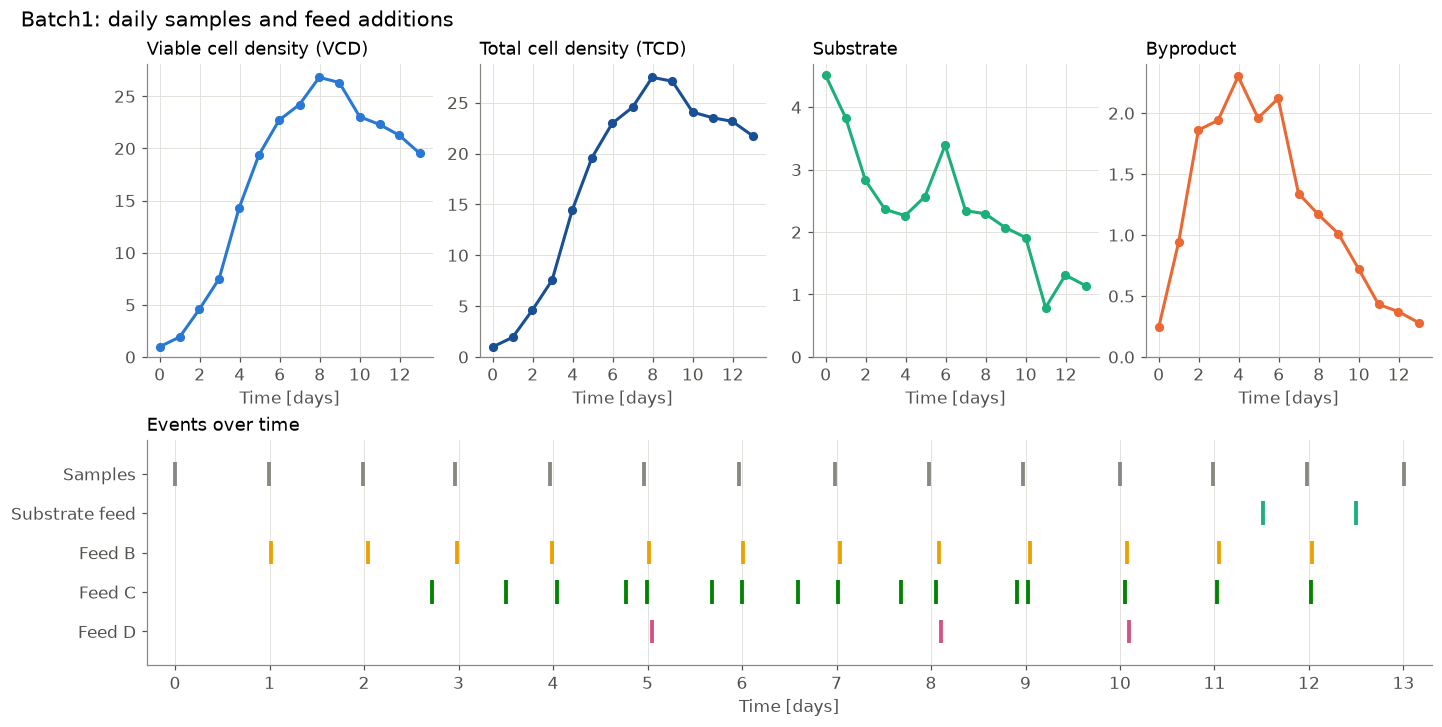

In [23]:
d = meas[meas["batch_id"] == "Batch1"] # samples of Batch1
ev = b["feed_events"] # feed additions of Batch1

fig = plt.figure(figsize=(13, 6.5), layout="constrained") # figure with automatic spacing
gs = fig.add_gridspec(2, 4, height_ratios=[1.3, 1]) # 4 panels on top, 1 wide panel below
for i, var in enumerate(data.TARGET_COLS): # one top panel per measured variable
    title, color = STYLE[var] # panel title and colour
    ax = fig.add_subplot(gs[0, i]) # top panel i
    ax.plot(d["elapsed_time"], d[var], color=color, lw=2, marker="o", ms=5) # daily samples
    ax.set(title=title, xlabel="Time [days]", xticks=DAYS, ylim=(0, None)) # titles and axes

ax = fig.add_subplot(gs[1, :]) # bottom panel, full width
rows = ["Samples"] + [STYLE[c][0] for c in data.FEED_COLS] # one row per event type
times = [d["elapsed_time"]] + [ev.loc[ev["feed"] == c, "elapsed_time"] for c in data.FEED_COLS] # event times per row
colors = [GREY] + [STYLE[c][1] for c in data.FEED_COLS] # colour per row
ax.eventplot(times, lineoffsets=range(len(rows)), linelengths=0.6, linewidths=2.5, colors=colors) # one tick per event
ax.set_yticks(range(len(rows)), rows) # row labels
ax.invert_yaxis() # samples on top
ax.set(title="Events over time", xlabel="Time [days]", xticks=range(14), xlim=(-0.3, 13.3)) # titles and axes
ax.grid(axis="y", visible=False) # vertical grid lines only

fig.suptitle("Batch1: daily samples and feed additions", x=0.01, ha="left", fontsize=14) # figure title
fig.savefig(FIG_DIR / "01_batch1_overview.png") # save as PNG
plt.show() # display

### 6.2 All training batches
Each thin line is one training batch; the thick line is the median over batches, per day. The spread of the thin lines shows the batch-to-batch variability the models must reproduce.

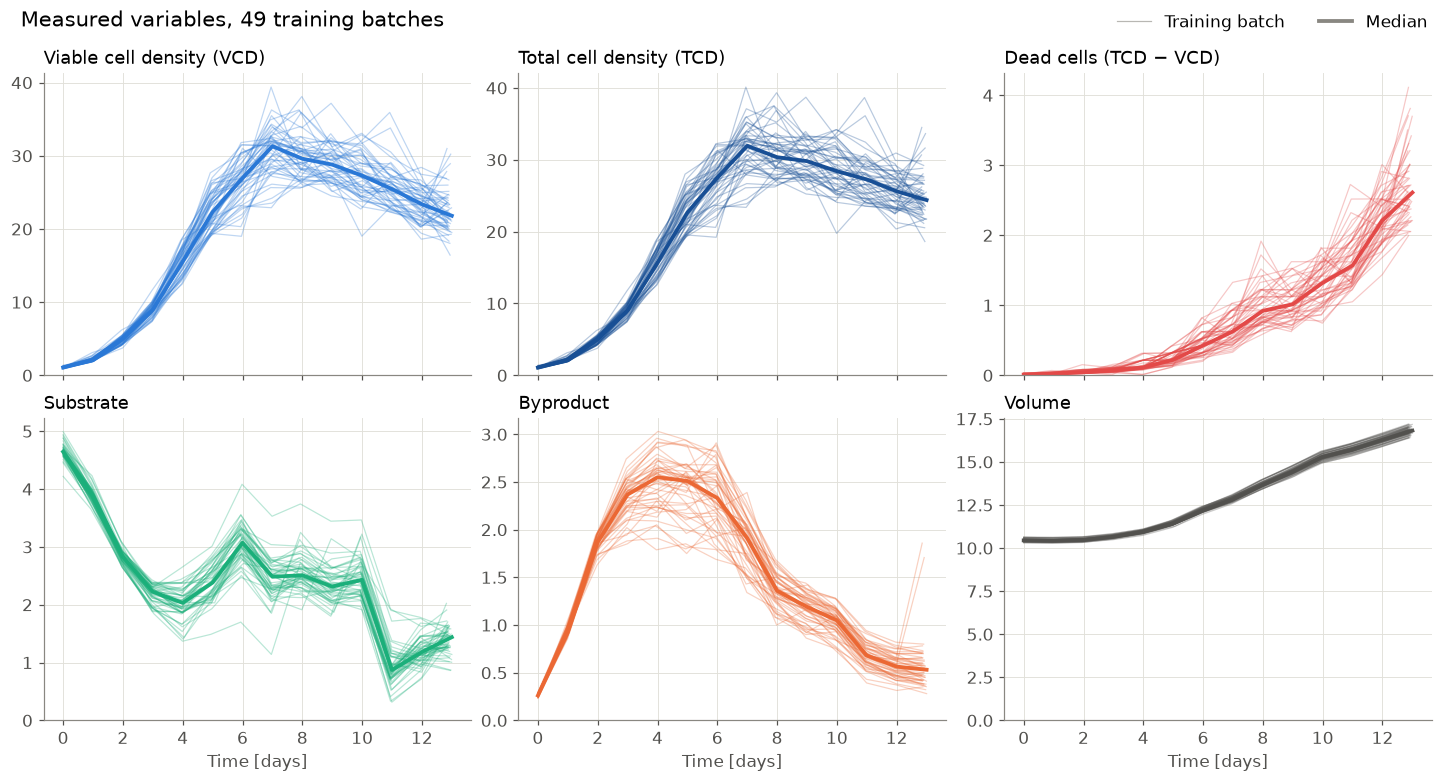

In [12]:
train = meas[~meas["is_test"]].assign(dead=lambda x: x["tcd"] - x["vcd"]) # training samples, plus dead cells
day = train["elapsed_time"].round() # sample day, to align batches
variables = ["vcd", "tcd", "dead", "substrate", "byproduct", "volume"] # one panel each

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, layout="constrained") # 2 x 3 panels
for ax, var in zip(axes.flat, variables): # one panel per variable
    title, color = STYLE[var] # panel title and colour
    for _, g in train.groupby("batch_id"): # every training batch
        ax.plot(g["elapsed_time"], g[var], color=color, lw=0.8, alpha=0.3) # thin light line
    med = train.groupby(day)[var].median() # median over batches, per day
    ax.plot(med.index, med, color=color, lw=2.5) # thick median line
    ax.set(title=title, xticks=DAYS, ylim=(0, None)) # titles and axes
for ax in axes[1]: # bottom row
    ax.set_xlabel("Time [days]") # x label

handles = [Line2D([], [], color=GREY, lw=0.8, alpha=0.6), Line2D([], [], color=GREY, lw=2.5)] # legend entries: thin and thick line
fig.legend(handles, ["Training batch", "Median"], loc="outside upper right", ncol=2) # legend above the panels
fig.suptitle(f"Measured variables, {len(train_ids)} training batches", x=0.01, ha="left", fontsize=14) # figure title
fig.savefig(FIG_DIR / "02_training_batches.png") # save as PNG
plt.show() # display

**Trends**
- **VCD**: fast growth for about one week, peak around day 7–8, then slow decline.
- **TCD** follows VCD; the gap between them (**dead cells**) grows mostly in the second half of the run.
- **Substrate**: drops quickly in the first 2–3 days, stays around a plateau until about day 10, then drops again.
- **Byproduct**: accumulates during growth (peak around day 3–5), then decreases.
- **Volume**: increases over the run, as feeds are added.

### 6.3 Feeding
Cumulative amount added per feed, for every batch: training batches in the feed colour, test batches in black. Each panel has its own scale (Feed C amounts are about 1000× smaller than Feed B). The test batches follow the same feeding schedules as the training batches.

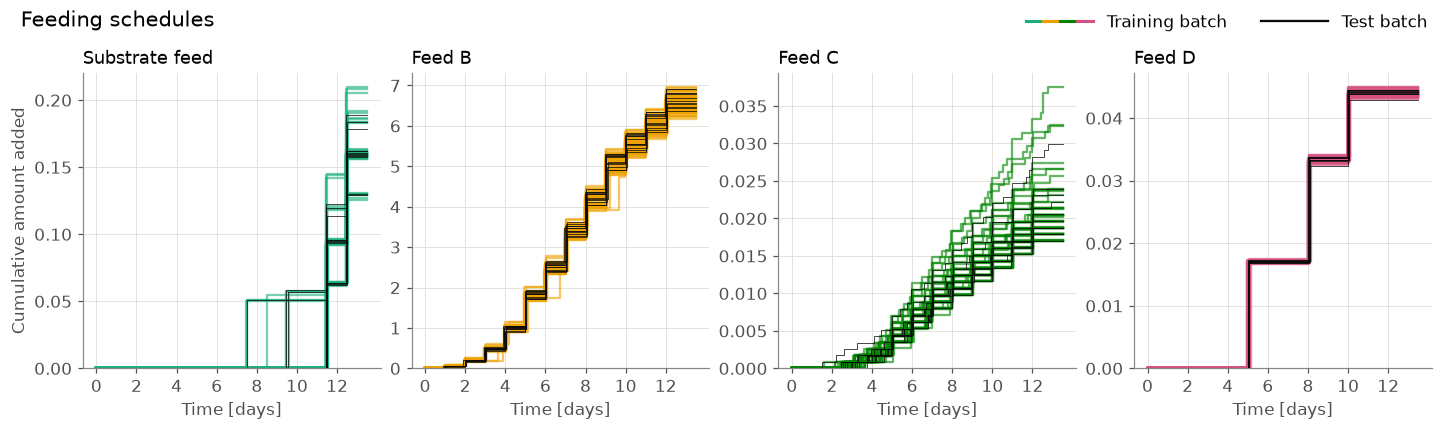

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharex=True, layout="constrained") # 4 panels in a row
for ax, col in zip(axes, data.FEED_COLS): # one panel per feed
    title, color = STYLE[col] # panel title and colour
    for (bid, is_test), g in feeds.groupby(["batch_id", "is_test"]): # every batch
        t = np.r_[0, g["elapsed_time"], 13.5] # event times, from start to end of run
        y = np.r_[0, g[col].cumsum(), g[col].sum()] # cumulative amount at those times
        style = dict(color=INK, lw=0.6, alpha=0.8, zorder=3) if is_test else dict(color=color, lw=1.5, alpha=0.6) # test: black on top; training: feed colour
        ax.step(t, y, where="post", **style) # step line: jumps at each addition
    ax.set(title=title, xlabel="Time [days]", xticks=DAYS, ylim=(0, None)) # titles and axes
axes[0].set_ylabel("Cumulative amount added") # y label on first panel

train_handle = tuple(Line2D([], [], color=STYLE[c][1], lw=2) for c in data.FEED_COLS) # one segment per feed colour
handles = [train_handle, Line2D([], [], color=INK, lw=1.5)] # legend entries
fig.legend(handles, ["Training batch", "Test batch"], handler_map={tuple: HandlerTuple(ndivide=None, pad=0)}, handlelength=4, loc="outside upper right", ncol=2) # legend above the panels
fig.suptitle("Feeding schedules", x=0.01, ha="left", fontsize=14) # figure title
fig.savefig(FIG_DIR / "03_feeding.png") # save as PNG
plt.show() # display

**Feeding pattern**
- **Feed B**: once a day from day 1, the largest additions; it accounts for most of the volume increase.
- **Feed C**: very small doses from about day 2–3, plus a larger (about double) dose once a day from day 5.
- **Feed D**: three additions, around days 5, 8 and 10.
- **Substrate feed**: only at the end of the run (around days 11.5 and 12.5).